## Assignment 1: Data Profiling
### Group Member:
1. AHMAD IRFAN FAIZI BIN MOHD YUSRI (A211206)
2. MUHAMMAD ZAHIN HANAFI BIN ROSGAIDDIN (A211415)
3. MUHAMMAD NAUFAL RIZQI AULIYA (A222945)
4. ZUL RIZA BIN IDRIS (A212679)


### SCENARIO
PropertyWise, a consulting company which help customer identify potential residential property investment opportunities in Hulu Langat, Selangor by using property transaction data obtained from the National Property Information Centre (NAPIC), Malaysia. Before using the dataset, the consultancy needs to evaluate its quality and identify issues that could affect the reliability of subsequent analysis.

### Business Question
Is the dataset that obtained from NAPIC is consistent and accurate enough to be used in property transaction analysis?

### Data Source
Source: National Property Information Centre, NAPIC

URL: https://napic.jpph.gov.my/ms/data-transaksi?category=36&id=241





### 1. Data Profiling and Issue Handling
Initial data profiling was conducted to understand the dataset's structure and assess the completeness of its attributes. The analysis examines data types, non-null records and unique values to identify potential data quality issues that require further investigation.

In [173]:
import os
import pandas as pd

# Load the NAPIC property transaction dataset
df = pd.read_csv(
    "../data/Dataset_PropWise1.csv",
    encoding="utf-16",
    sep="\t"
)

# Initial inspection of the NAPIC dataset

print("Dataset Overview")
print("-----------------")
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

# Display the first five records

display(df.head())

# Display all column names

print("Dataset Columns:")
for column in df.columns:
    print("-", repr(column))



Dataset Overview
-----------------
Total records: 1845
Total columns: 14


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Unit,Main Floor Area,Unit,Unit Level,Transaction Price,Unnamed: 13
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,,April 2026,Leasehold,70.0,sq.m,-,-,1,"RM267,000.00",NaN
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATok AHMAD RAZALI,,April 2026,Leasehold,85.0,sq.m,-,-,G,"RM400,000.00",NaN
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,April 2026,Leasehold,107.0,sq.m,-,-,2,"RM450,000.00",NaN
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,May 2026,Leasehold,100.0,sq.m,-,-,1,"RM390,000.00",NaN
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,,August 2025,Leasehold,82.0,sq.m,-,-,4&5,"RM330,000.00",NaN


Dataset Columns:
- 'Property Type'
- 'District'
- 'Mukim'
- 'Scheme Name/Area'
- 'Road Name'
- 'Month, Year of Transaction Date'
- 'Tenure'
- 'Land/Parcel Area'
- 'Unit'
- 'Main Floor Area'
- 'Unit        '
- 'Unit Level'
- 'Transaction Price  '
- 'Unnamed: 13'


In [174]:
profile = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Unique Values": df.nunique().values
})

display(profile)

,Column,Data Type,Non-Null Count,Unique Values
0,Property Type,str,1845,1
1,District,str,1840,1
2,Mukim,str,1845,17
3,Scheme Name/Area,str,1845,221
4,Road Name,str,1845,1
5,"Month, Year of Transaction Date",str,1845,30
6,Tenure,str,1845,2
7,Land/Parcel Area,float64,1845,198
8,Unit,str,1845,1
9,Main Floor Area,str,1845,1


In [175]:
import numpy as np

df_clean = df.copy()

# Convert empty strings and whitespace-only values to NaN
df_clean = df_clean.replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# Convert hyphen placeholders to NaN
df_clean = df_clean.replace("-", np.nan)

print("Missing-value placeholders converted to NaN.")

Missing-value placeholders converted to NaN.


In [176]:
missing_table = pd.DataFrame({
    "Column": df_clean.columns,
    "Missing Count": df_clean.isnull().sum().values,
    "Missing Percentage": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

missing_table = missing_table.sort_values(
    "Missing Count",
    ascending=False
)

display(missing_table)

,Column,Missing Count,Missing Percentage
4,Road Name,1845,100.00
9,Main Floor Area,1845,100.00
10,Unit,1845,100.00
13,Unnamed: 13,1845,100.00
1,District,5,0.27
0,Property Type,0,0.00
5,"Month, Year of Transaction Date",0,0.00
3,Scheme Name/Area,0,0.00
2,Mukim,0,0.00
6,Tenure,0,0.00


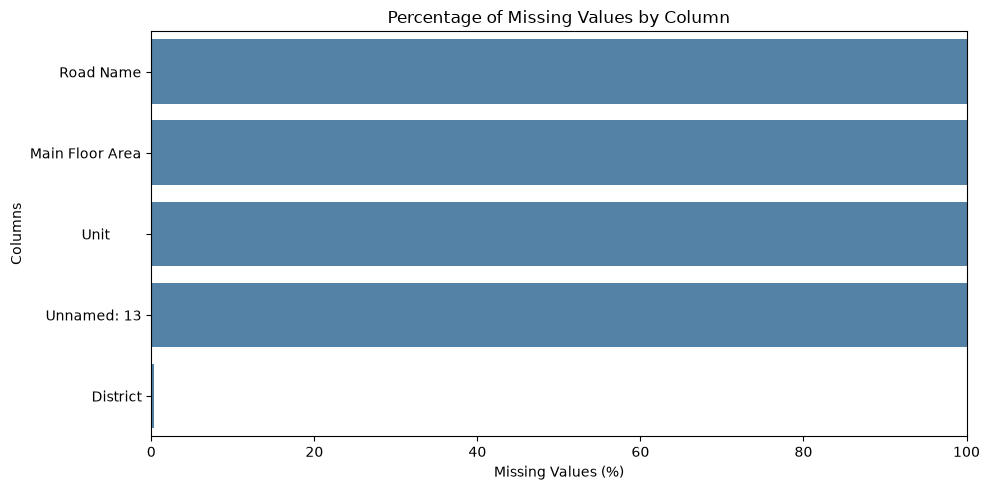

In [177]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_plot = missing_table[
    missing_table["Missing Count"] > 0
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_plot,
    x="Missing Percentage",
    y="Column",
    color="steelblue"
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

#### Data Profiling Finding
The initial data profiling examined the dataset's structure, data types, unique values and completeness across 1,845 records and 14 columns. The analysis identified potential data quality issues involving missing values and column structure.

The missing-value analysis revealed that four columns had 100% missing values, affecting all 1,845 records. These columns were Road Name, Main Floor Area, Unit and Unnamed: 13. The remaining columns showed 0% missing values based on the current profiling results.

The initial profiling also identified an unnamed column with no non-null values and two columns labelled [Unit]. These findings indicate potential structural issues that require further investigation. In addition, several categorical attributes, including Property Type, District and Road Name, had only one unique value in the initial profiling results, which may indicate limited variation or missing information.

Overall, the results highlight potential completeness and structural issues that should be investigated before the dataset is used for further analysis. The next stage will verify the affected columns and examine other data quality issues, including invalid values, inconsistencies and potential outliers, before determining the appropriate data cleaning methods.


In [178]:
import numpy as np
import pandas as pd

print("DATA CLEANING & OTHER QUALITY ISSUES")

# Preserve the original dataset
df_clean = df.copy()

# Remove leading and trailing spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Rename duplicate Unit columns by position
cols = list(df_clean.columns)
cols[8] = "Land Area Unit"
cols[10] = "Main Floor Unit"
df_clean.columns = cols

print("Working copy created.")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

display(df_clean.head())

DATA CLEANING & OTHER QUALITY ISSUES
Working copy created.
Original dataset shape: (1845, 14)
Working dataset shape: (1845, 14)


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price,Unnamed: 13
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,,April 2026,Leasehold,70.0,sq.m,-,-,1,"RM267,000.00",NaN
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATok AHMAD RAZALI,,April 2026,Leasehold,85.0,sq.m,-,-,G,"RM400,000.00",NaN
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,April 2026,Leasehold,107.0,sq.m,-,-,2,"RM450,000.00",NaN
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,May 2026,Leasehold,100.0,sq.m,-,-,1,"RM390,000.00",NaN
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,,August 2025,Leasehold,82.0,sq.m,-,-,4&5,"RM330,000.00",NaN


In [179]:
print("1. Fixing Invalid Values:")

# Remove the unnamed column if it is entirely empty
if "Unnamed: 13" in df_clean.columns:
    if df_clean["Unnamed: 13"].isna().all():
        df_clean = df_clean.drop(columns=["Unnamed: 13"])
        print("Removed the completely empty Unnamed: 13 column.")

# Convert blank strings and selected placeholders into NaN
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].replace(
        r"^\s*$",
        np.nan,
        regex=True
    )

    df_clean[col] = df_clean[col].replace(
        ["-", "nan", "NAN"],
        np.nan
    )

print("Converted blank strings and selected placeholders to NaN.")

display(df_clean.head())

1. Fixing Invalid Values:
Removed the completely empty Unnamed: 13 column.
Converted blank strings and selected placeholders to NaN.


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,NaN,NaN,1,"RM267,000.00"
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATok AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,NaN,NaN,G,"RM400,000.00"
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,NaN,NaN,2,"RM450,000.00"
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,NaN,NaN,1,"RM390,000.00"
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,NaN,NaN,4&5,"RM330,000.00"


In [180]:
print("Original Main Floor Area:")
print(df["Main Floor Area"].head(10))

print("\nCleaned Main Floor Area:")
print(df_clean["Main Floor Area"].head(10))

print("\nMissing values before cleaning:",
      df["Main Floor Area"].isna().sum())

print("Missing values after cleaning:",
      df_clean["Main Floor Area"].isna().sum())

Original Main Floor Area:
0    -
1    -
2    -
3    -
4    -
5    -
6    -
7    -
8    -
9    -
Name: Main Floor Area, dtype: str

Cleaned Main Floor Area:
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
Name: Main Floor Area, dtype: str

Missing values before cleaning: 0
Missing values after cleaning: 1845


In [181]:
print("Original column count:", len(df.columns))
print("Cleaned column count:", len(df_clean.columns))

print("\nNew columns:")
print(sorted(set(df_clean.columns) - set(df.columns)))

print("\nRemoved columns:")
print(sorted(set(df.columns) - set(df_clean.columns)))

Original column count: 14
Cleaned column count: 13

New columns:
['Land Area Unit', 'Main Floor Unit', 'Transaction Price']

Removed columns:
['Transaction Price  ', 'Unit', 'Unit        ', 'Unnamed: 13']


In [182]:
print("2. Fixing Inconsistent Formats:")

# Standardise spacing in text columns
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].apply(
        lambda x: " ".join(x.split()) if isinstance(x, str) else x
    )

# Standardise selected abbreviations in Scheme Name/Area
if "Scheme Name/Area" in df_clean.columns:
    df_clean["Scheme Name/Area"] = (
        df_clean["Scheme Name/Area"]
        .str.upper()
        .str.replace(r"\bTMN\b", "TAMAN", regex=True)
        .str.replace(r"\bJLN\b", "JALAN", regex=True)
    )

print("Standardised spacing and selected abbreviations.")

print(
    "Unique Scheme Names/Areas:",
    df_clean["Scheme Name/Area"].nunique()
)

display(df_clean.head())

2. Fixing Inconsistent Formats:
Standardised spacing and selected abbreviations.
Unique Scheme Names/Areas: 198


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,NaN,NaN,1,"RM267,000.00"
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,NaN,NaN,G,"RM400,000.00"
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,NaN,NaN,2,"RM450,000.00"
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,NaN,NaN,1,"RM390,000.00"
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,NaN,NaN,4&5,"RM330,000.00"


In [183]:
print("3. Fixing Wrong Data Types:")

# Convert land/parcel area to numeric
df_clean["Land/Parcel Area"] = pd.to_numeric(
    df_clean["Land/Parcel Area"]
    .astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# Convert main floor area to numeric
df_clean["Main Floor Area"] = pd.to_numeric(
    df_clean["Main Floor Area"]
    .astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# Convert transaction price to numeric
df_clean["Transaction Price"] = pd.to_numeric(
    df_clean["Transaction Price"]
    .astype("string")
    .str.replace("RM", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Convert transaction month/year into a date
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Month, Year of Transaction Date"],
    format="%B %Y",
    errors="coerce"
)

print("Data type conversion completed.")


print(
    df_clean[
        [
            "Land/Parcel Area",
            "Main Floor Area",
            "Transaction Price",
            "Transaction Date"
        ]
    ].dtypes
)

display(df_clean.head())


3. Fixing Wrong Data Types:
Data type conversion completed.
Land/Parcel Area            Float64
Main Floor Area             Float64
Transaction Price           Float64
Transaction Date     datetime64[us]
dtype: object


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price,Transaction Date
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,<NA>,NaN,1,267000.0,2026-04-01
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,<NA>,NaN,G,400000.0,2026-04-01
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,<NA>,NaN,2,450000.0,2026-04-01
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,<NA>,NaN,1,390000.0,2026-05-01
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,<NA>,NaN,4&5,330000.0,2025-08-01


In [184]:
print("4. Handling Duplicates:")

rows_before = len(df_clean)

duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows detected:", duplicate_count)

df_clean = df_clean.drop_duplicates(
    keep="first"
).reset_index(drop=True)

rows_after = len(df_clean)

print("Duplicate rows removed:", rows_before - rows_after)
print("Rows remaining:", rows_after)

display(df_clean.head())

4. Handling Duplicates:
Duplicate rows detected: 4
Duplicate rows removed: 4
Rows remaining: 1841


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price,Transaction Date
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,<NA>,NaN,1,267000.0,2026-04-01
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,<NA>,NaN,G,400000.0,2026-04-01
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,<NA>,NaN,2,450000.0,2026-04-01
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,<NA>,NaN,1,390000.0,2026-05-01
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,<NA>,NaN,4&5,330000.0,2025-08-01


In [185]:
print("OUTLIER DETECTION & HANDLING")

num_cols = [
    "Transaction Price",
    "Land/Parcel Area",
    "Main Floor Area"
]

outlier_stats = []

for col in num_cols:
    s = df_clean[col].dropna()

    if len(s) == 0:
        print(f"Skipping {col}: no valid numeric values.")
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    iqr_outliers = int(
        ((s < lower_bound) | (s > upper_bound)).sum()
    )

    std = s.std()

    if std > 0:
        z_outliers = int(
            (((s - s.mean()) / std).abs() > 3).sum()
        )
    else:
        z_outliers = 0

    outlier_stats.append({
        "Column": col,
        "Q1": round(q1, 2),
        "Median": round(s.median(), 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower Fence": round(lower_bound, 2),
        "Upper Fence": round(upper_bound, 2),
        "IQR Outliers": iqr_outliers,
        "IQR Outlier (%)": round(
            iqr_outliers / len(s) * 100, 2
        ),
        "Z-Score Outliers": z_outliers
    })

outlier_summary_df = pd.DataFrame(outlier_stats)

display(outlier_summary_df)

OUTLIER DETECTION & HANDLING
Skipping Main Floor Area: no valid numeric values.


,Column,Q1,Median,Q3,IQR,Lower Fence,Upper Fence,IQR Outliers,IQR Outlier (%),Z-Score Outliers
0,Transaction Price,280000.0,350000.0,448000.0,168000.0,28000.0,700000.0,45,2.44,23
1,Land/Parcel Area,82.0,92.0,106.0,24.0,46.0,142.0,112,6.08,22


In [186]:
print("INVESTIGATING POTENTIALLY INVALID RECORDS")

# Property categories that may represent strata properties
strata_types = [
    "Condominium/Apartment",
    "Flat",
    "Low-Cost Flat",
    "Town House"
]

is_strata = df_clean["Property Type"].isin(strata_types)

# Potentially implausible floor area
corrupted_floor = (
    df_clean["Main Floor Area"].notna()
    & (~is_strata)
    & (
        (df_clean["Main Floor Area"] > 3000)
        | (
            df_clean["Main Floor Area"]
            > df_clean["Land/Parcel Area"] * 5
        )
    )
)

# Potentially unusual land area for non-strata properties
small_land_area = (
    df_clean["Land/Parcel Area"].notna()
    & (~is_strata)
    & (df_clean["Land/Parcel Area"] < 30)
)

# Potentially misclassified low-cost property records
low_cost_types = [
    "Low-Cost Flat",
    "Low-Cost House"
]

potentially_misclassified = (
    df_clean["Property Type"].isin(low_cost_types)
    & (
        (df_clean["Transaction Price"] > 1_000_000)
        | (df_clean["Land/Parcel Area"] > 500)
    )
)

print("Potentially unusual floor area:", corrupted_floor.sum())
print("Potentially unusual land area:", small_land_area.sum())
print(
    "Potentially misclassified low-cost records:",
    potentially_misclassified.sum()
)

INVESTIGATING POTENTIALLY INVALID RECORDS
Potentially unusual floor area: 0
Potentially unusual land area: 0
Potentially misclassified low-cost records: 0


In [187]:
def flag_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return (series < lower) | (series > upper)


df_clean["Is_Price_Outlier"] = (
    df_clean.groupby("Property Type")["Transaction Price"]
    .transform(flag_iqr)
    .fillna(False)
    .astype(bool)
)

print(
    "Potential price outliers flagged:",
    df_clean["Is_Price_Outlier"].sum()
)

display(
    df_clean.loc[
        df_clean["Is_Price_Outlier"],
        [
            "Property Type",
            "Transaction Price",
            "Is_Price_Outlier"
        ]
    ].head(10)
)

Potential price outliers flagged: 45


,Property Type,Transaction Price,Is_Price_Outlier
118,Condominium/Apartment,750000.0,True
225,Condominium/Apartment,840000.0,True
261,Condominium/Apartment,800000.0,True
604,Condominium/Apartment,735000.0,True
972,Condominium/Apartment,810000.0,True
998,Condominium/Apartment,715000.0,True
1027,Condominium/Apartment,860000.0,True
1092,Condominium/Apartment,809000.0,True
1152,Condominium/Apartment,1476000.0,True
1161,Condominium/Apartment,900000.0,True


In [188]:
def cap_prices(series):
    lower = series.quantile(0.01)
    upper = series.quantile(0.99)

    return series.clip(
        lower=lower,
        upper=upper
    )


df_clean["Transaction Price (Capped)"] = (
    df_clean.groupby("Property Type")["Transaction Price"]
    .transform(cap_prices)
)

print("Original and capped transaction prices:")

display(
    df_clean[
        [
            "Property Type",
            "Transaction Price",
            "Transaction Price (Capped)",
            "Is_Price_Outlier"
        ]
    ].head(10)
)

Original and capped transaction prices:


,Property Type,Transaction Price,Transaction Price (Capped),Is_Price_Outlier
0,Condominium/Apartment,267000.0,267000.0,False
1,Condominium/Apartment,400000.0,400000.0,False
2,Condominium/Apartment,450000.0,450000.0,False
3,Condominium/Apartment,390000.0,390000.0,False
4,Condominium/Apartment,330000.0,330000.0,False
5,Condominium/Apartment,290000.0,290000.0,False
6,Condominium/Apartment,250000.0,250000.0,False
7,Condominium/Apartment,350000.0,350000.0,False
8,Condominium/Apartment,315000.0,315000.0,False
9,Condominium/Apartment,280000.0,280000.0,False


In [189]:
before_after_df = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total columns",
        "Unique scheme names/areas",
        "Unique road names",
        "Transaction price data type",
        "Missing transaction prices",
        "Missing land/parcel areas",
        "Missing main floor areas"
    ],
    "Before Cleaning": [
        len(df),
        df.shape[1],
        df["Scheme Name/Area"].nunique(),
        df["Road Name"].nunique(),
        str(df["Transaction Price"].dtype)
            if "Transaction Price" in df.columns
            else "Column not found",
        df["Transaction Price"].isna().sum()
            if "Transaction Price" in df.columns
            else None,
        df["Land/Parcel Area"].isna().sum(),
        df["Main Floor Area"].isna().sum()
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.shape[1],
        df_clean["Scheme Name/Area"].nunique(),
        df_clean["Road Name"].nunique(),
        str(df_clean["Transaction Price"].dtype),
        df_clean["Transaction Price"].isna().sum(),
        df_clean["Land/Parcel Area"].isna().sum(),
        df_clean["Main Floor Area"].isna().sum()
    ]
})

display(before_after_df)

,Metric,Before Cleaning,After Cleaning
0,Total rows,1845,1841
1,Total columns,14,16
2,Unique scheme names/areas,221,198
3,Unique road names,1,0
4,Transaction price data type,Column not found,Float64
5,Missing transaction prices,None,0
6,Missing land/parcel areas,0,0
7,Missing main floor areas,0,1841


### Data Cleaning and Outlier Handling
The data cleaning process shows missing values, inconsistent text formatting, data types and duplicate records. A separate working copy was created to preserve the original dataset. During duplicate detection, four duplicate records were identified and removed, reducing the dataset from 1,845 to 1,841 records.

Text standardisation reduced the number of unique Scheme Name/Area values from 221 to 198, representing a reduction of approximately 10.41%. Placeholder values, including hyphens (-) and blank entries, were converted into recognised missing values. Following cleaning, the Road Name and Main Floor Area columns contained no usable information across the 1,841 remaining records.

Numeric data types were standardised, including converting Transaction Price into a numeric format and transaction dates into a date format. Potential outliers were investigated using the Interquartile Range (IQR) and Z-score methods, with additional checks for unusually large floor areas, small land areas and potentially misclassified property records. Statistical outliers were not automatically removed, as unusual property prices may represent legitimate transactions.

The before-and-after comparison summarises the changes made and the remaining data quality limitations. The original transaction prices were retained for traceability, while a separate capped price column was created to reduce the influence of extreme values in subsequent analysis.



### 2. Exploratory (Diagnostic) Charts

#### a) Transaction Price Distribution
A histogram is used to examine the distribution of property transaction prices and identify potential extreme values. This visualisation helps assess the spread of transaction prices and understand whether the dataset contains unusually high or low values.

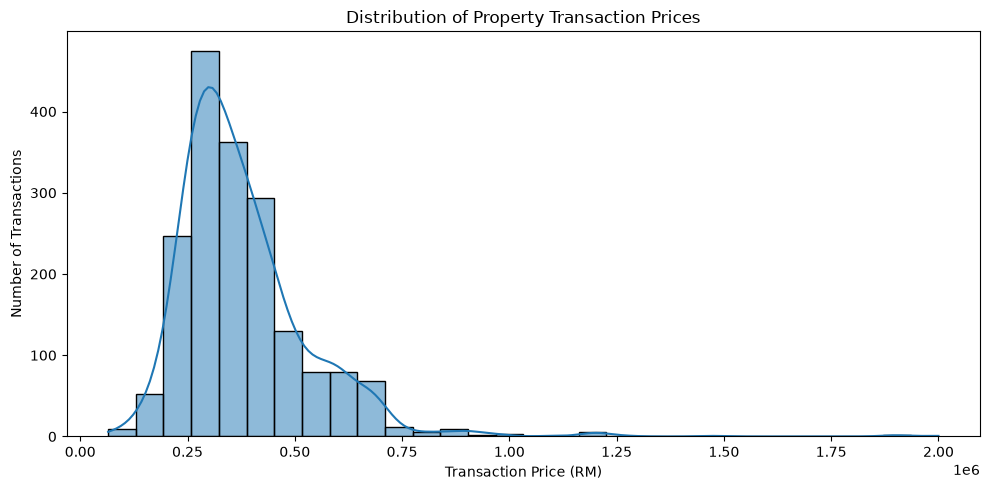

In [190]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select valid transaction prices
price_data = df_clean["Transaction Price"].dropna()

# Create histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    price_data,
    bins=30,
    kde=True
)

plt.title("Distribution of Property Transaction Prices")
plt.xlabel("Transaction Price (RM)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

The histogram illustrates the distribution of property transaction prices, showing a positively skewed (right-skewed) distribution. Most transactions are concentrated between approximately RM250,000 and RM450,000, while a smaller number of properties have significantly higher transaction values, with some approaching RM2 million. These extreme values may indicate potential outliers and require further investigation. However, high transaction prices are not necessarily data errors, as they may represent legitimate property transactions.

#### b) Transaction Price Outlier Detection

A boxplot is used to examine the spread of property transaction prices and identify potential outliers. The visualisation highlights the median, interquartile range and unusually high or low transaction values that may require further investigation.

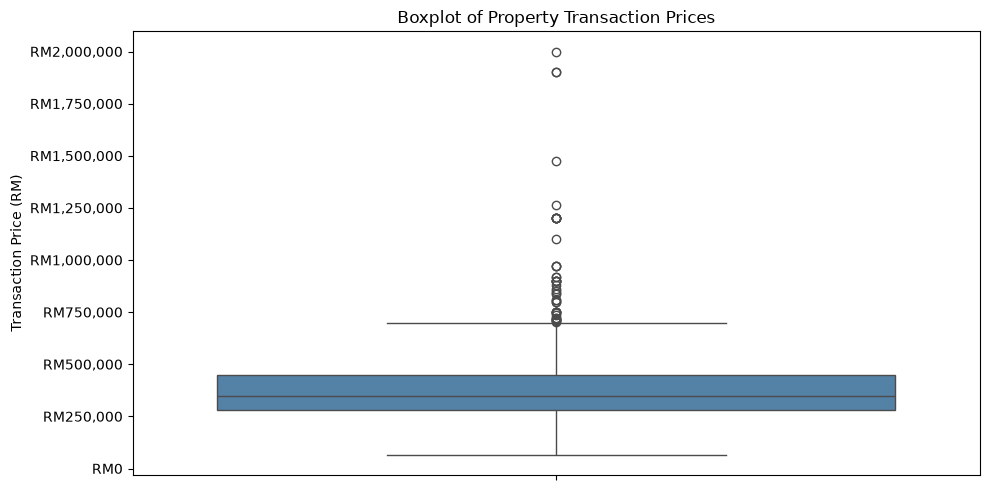

In [191]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(10, 5))

sns.boxplot(
    y=df_clean["Transaction Price"],
    color="steelblue"
)

plt.title("Boxplot of Property Transaction Prices")
plt.ylabel("Transaction Price (RM)")

# Display values in Malaysian Ringgit
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'RM{x:,.0f}')
)

plt.tight_layout()
plt.show()

The boxplot illustrates the distribution of property transaction prices and highlights potential outliers. Most transactions fall within approximately RM280,000 to RM450,000, with a median price of around RM350,000. Several transactions exceed the upper whisker of approximately RM700,000, with some approaching RM2 million. These extreme values may influence statistical analysis and require further investigation. However, they should not automatically be classified as errors, as they may represent legitimate high-value property transactions.

### 3) PII And Bias Risks

#### a) PII and Privacy Assessment
This assessment examines the dataset for personally identifiable information (PII) and potential privacy risks. It considers whether the available property transaction attributes could directly or indirectly identify individuals.


In [192]:
# Inspect dataset columns for potential PII

print("Dataset Columns:")
for col in df_clean.columns:
    print("-", col)

# Potential direct identifiers to investigate
potential_pii = [
    "Name",
    "Owner Name",
    "Buyer Name",
    "Seller Name",
    "IC Number",
    "Identification Number",
    "Phone Number",
    "Email",
    "Address"
]

identified_pii = [
    col for col in df_clean.columns
    if col.strip().lower() in [
        name.lower() for name in potential_pii
    ]
]

print("\nPotential Direct PII Fields Found:")

if identified_pii:
    print(identified_pii)
else:
    print("No matching direct PII fields identified.")

Dataset Columns:
- Property Type
- District
- Mukim
- Scheme Name/Area
- Road Name
- Month, Year of Transaction Date
- Tenure
- Land/Parcel Area
- Land Area Unit
- Main Floor Area
- Main Floor Unit
- Unit Level
- Transaction Price
- Transaction Date
- Is_Price_Outlier
- Transaction Price (Capped)

Potential Direct PII Fields Found:
No matching direct PII fields identified.


In [193]:
# Identify potentially sensitive combinations of attributes

quasi_identifiers = [
    "Scheme Name/Area",
    "Mukim",
    "Transaction Date",
    "Land/Parcel Area",
    "Transaction Price"
]

# Check which columns are available
available_columns = [
    col for col in quasi_identifiers
    if col in df_clean.columns
]

# Count unique combinations
unique_combinations = df_clean[
    available_columns
].drop_duplicates().shape[0]

total_records = len(df_clean)

print("Total records:", total_records)
print("Unique attribute combinations:", unique_combinations)

print(
    "Percentage of unique combinations:",
    round(unique_combinations / total_records * 100, 2),
    "%"
)

Total records: 1841
Unique attribute combinations: 1764
Percentage of unique combinations: 95.82 %


The assessment found no direct personally identifiable information (PII), such as individual names, identification numbers, telephone numbers or email addresses, within the dataset. However, certain attributes, including property location, transaction date, land area and transaction price, may act as indirect identifiers when combined.

An assessment of five selected attributes identified 1,764 unique combinations across 1,841 records, representing approximately 95.82% of the dataset. This indicates that many transaction records have distinctive attribute combinations, potentially increasing the risk of re-identification when linked with external information.

Although no direct personal identifiers were identified, the dataset may still present privacy risks due to the combination of geographical and transaction details. Therefore, appropriate data protection measures, such as limiting access and aggregating sensitive information where necessary, should be considered before sharing or publishing the dataset.


#### b) Bias Assessment
#### b.i) Geographical Representation
This assessment examines the geographical distribution of property transactions to identify whether the dataset represents multiple districts and areas equally or is concentrated within a limited geographical scope.


In [194]:
# Analyse geographical representation

print("Number of Districts:",
      df_clean["District"].nunique())

print("\nTransaction Records by District:")
display(
    df_clean["District"].value_counts()
)

print("\nNumber of Mukim Areas:",
      df_clean["Mukim"].nunique())

print("\nTransaction Records by Mukim:")
display(
    df_clean["Mukim"].value_counts().head(20)
)

Number of Districts: 1

Transaction Records by District:


District
Hulu Langat    1836
Name: count, dtype: int64


Number of Mukim Areas: 17

Transaction Records by Mukim:


Mukim
Bandar Ampang              321
Cheras                     274
Kajang                     181
Bandar Baru Bangi          153
Bandar Cheras              153
Pekan Cheras               125
Hulu Langat                106
Bandar Kajang               92
Pekan Kajang                91
Semenyih                    90
Beranang                    82
Ampang                      77
Pekan Kg Sungai Tangkas     39
Pekan Semenyih              27
Pekan Bangi Lama            19
Bandar Batu 18 Semenyih      9
Pekan Sungai Makau           2
Name: count, dtype: int64

#### b.ii) Property Type Representation
This assessment will show the concentration of records in the single available property category.

In [195]:
# Analyse property-type representation

property_distribution = (
    df_clean["Property Type"]
    .value_counts()
    .reset_index()
)

property_distribution.columns = [
    "Property Type",
    "Transaction Count"
]

property_distribution["Percentage"] = (
    property_distribution["Transaction Count"]
    / len(df_clean) * 100
).round(2)

display(property_distribution)

,Property Type,Transaction Count,Percentage
0,Condominium/Apartment,1841,100.0


The geographical analysis identified that 1,836 out of 1,841 records (approximately 99.73%) were associated with Hulu Langat, covering 17 Mukim areas. However, transaction distribution across these areas was uneven, with Bandar Ampang recording the highest number of transactions (321), while Pekan Sungai Makau recorded the lowest which is only two. This geographical concentration limits the dataset's ability to represent property transaction patterns across other districts.

The property-type analysis showed that all 1,841 records (100%) belonged to the Condominium/Apartment category. So the dataset cannot support comparisons across different property types. These findings highlight potential geographical and property-type representation biases that should be considered when interpreting the dataset and applying its findings beyond the selected area and category.

### 4) Conclusion
The data profiling and quality assessment identified several issues within the NAPIC property transaction dataset. These included placeholder values, missing information in the Road Name and Main Floor Area columns, inconsistent naming formats and duplicate records. Data cleaning improved the dataset's consistency, while outlier analysis identified unusually high transaction prices requiring further investigation.

The visualisation results showed a positively skewed distribution of transaction prices, with several potential outliers. The PII assessment found no obvious direct personal identifiers.However, combinations of property location, transaction date, land area and transaction price may create potential re-identification risks. The bias assessment also identified geographical and property-type limitations, as the dataset primarily represents condominium/apartment transactions within Hulu Langat.

Overall, the dataset is partially suitable for further analysis, particularly for examining condominium/apartment transactions within the covered geographical areas. However, its missing information and potential privacy risks which makes it less suitable for further property market analysis.
